# N110 features for RankMe and variance forecasting

**Complete** · Finished all predictors · ETA 0h 00m 00s

Paired scores through 80,000 arrivals. seed 2026 at 80,000, seed 2027 at 80,000, seed 2028 at 80,000 Updated 2026-11-11T13:49:22+01:00.

## Paired RMSE over the stream

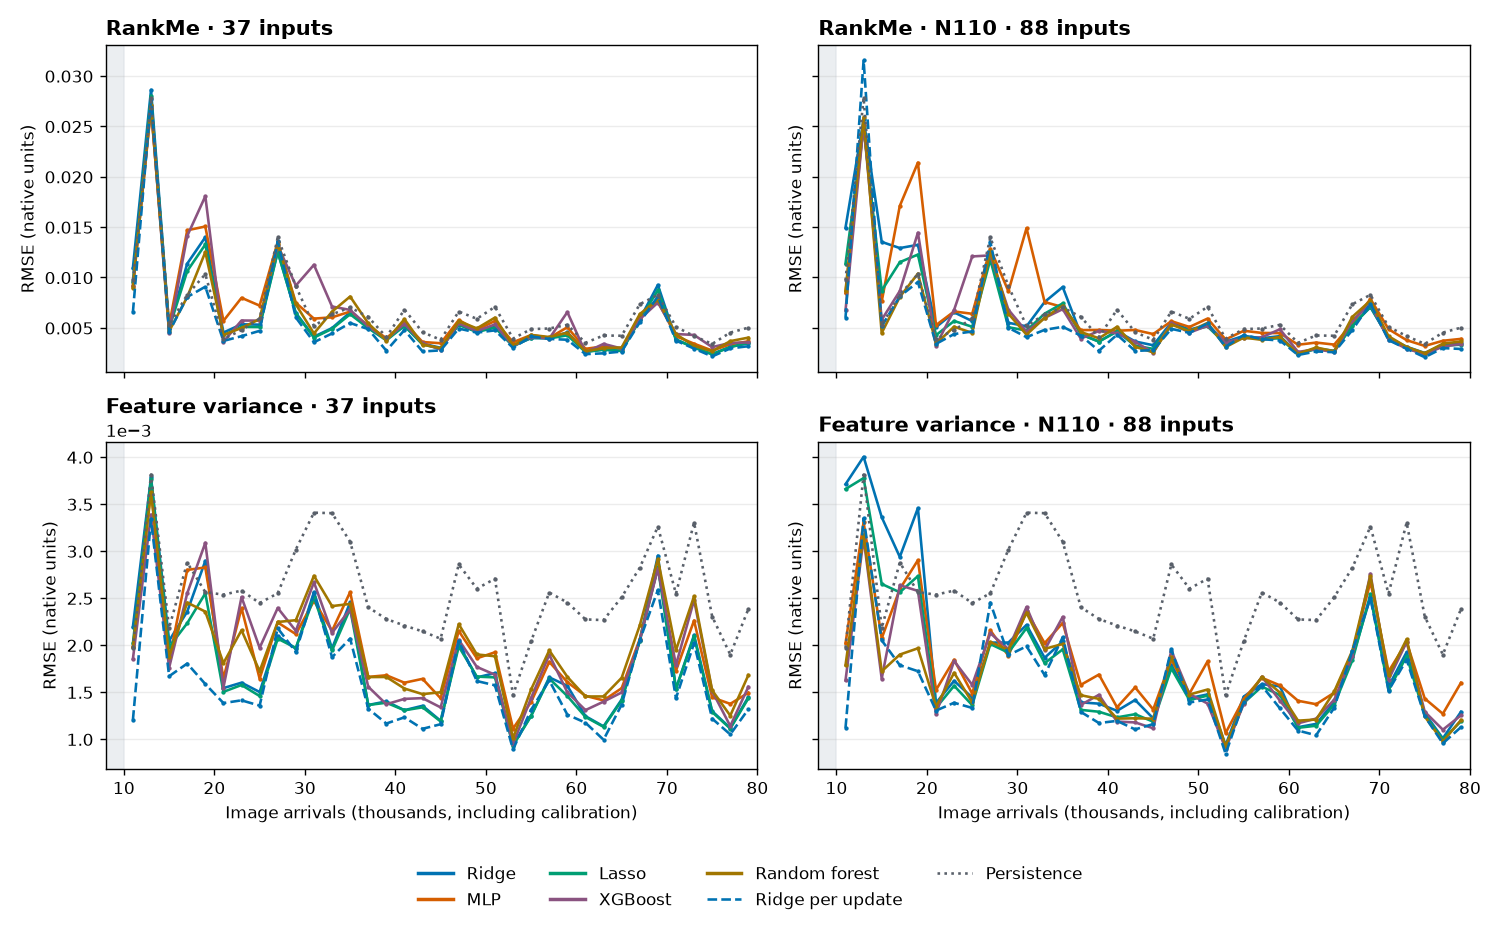

## Pooled held-out scores

| Predictor | Inputs | RankMe RMSE | Variance RMSE | RankMe gain vs persistence | Variance gain vs persistence |
| --- | --- | --- | --- | --- | --- |
 | Persistence | — | 0.00786233 | 0.00261077 | — | — | 
 | Ridge | 37 inputs | 0.00769063 | 0.00188881 | +2.2% | +27.7% | 
 | MLP | 37 inputs | 0.00795298 | 0.00200869 | -1.2% | +23.1% | 
 | Lasso | 37 inputs | 0.00744366 | 0.0018401 | +5.3% | +29.5% | 
 | XGBoost | 37 inputs | 0.00821337 | 0.00197781 | -4.5% | +24.2% | 
 | Random forest | 37 inputs | 0.00745397 | 0.00202805 | +5.2% | +22.3% | 
 | Ridge per update | 37 inputs | 0.00690346 | 0.00167716 | +12.2% | +35.8% | 
 | Ridge | N110 · 88 inputs | 0.00797918 | 0.00198751 | -1.5% | +23.9% | 
 | MLP | N110 · 88 inputs | 0.00874316 | 0.00188292 | -11.2% | +27.9% | 
 | Lasso | N110 · 88 inputs | 0.00721923 | 0.0018589 | +8.2% | +28.8% | 
 | XGBoost | N110 · 88 inputs | 0.0073241 | 0.00177346 | +6.8% | +32.1% | 
 | Random forest | N110 · 88 inputs | 0.00695484 | 0.00172017 | +11.5% | +34.1% | 
 | Ridge per update | N110 · 88 inputs | 0.00731174 | 0.00163997 | +7.0% | +37.2% | 

## Protocol

The same three seed checkpoints, balanced actions and 128-frame bank are shared across predictors. After measuring the update effect, one bank frame is replaced every 16 arrivals. RankMe and raw feature variance targets come from the slow-bank replay. N110 inputs use its retained 88 coordinates, including normalized embedding variance as an input, fixed-mask reconstruction, projection coordinates, and cluster-level summaries. A frozen calibration encoder supplies reference embeddings and assigns incoming members to the four calibration clusters. An empty group uses the whole bank’s summaries. All inputs are label-free.

The first 2,000 post-calibration arrivals provide warm-up. The five model families share the existing 4,000-arrival refit schedule, training history and hyperparameters. Lasso uses coordinate descent with the same penalty on both sets. The per-update Ridge starts from the identical Ridge fit at each boundary, forecasts each actual update before feedback, then updates the fit with an exponential half-life of 256 successful updates. Each point pools errors over seeds and 2,000 arrivals. Persistence predicts zero change. Skips are excluded from RMSE.

In [ ]:
# Run this cell to watch the background worker.
from IPython.display import clear_output, display, Image, Markdown
from pathlib import Path
import json, time

folder = Path('C:\\CAFL-E\\analysis\\2026-11-09-one-step-mpc\\n110-feature-benchmark')
while True:
    try:
        status = json.loads((folder / 'status.json').read_text(encoding='utf-8'))
        plot = (folder / 'rmse.png').read_bytes()
    except (PermissionError, FileNotFoundError):
        time.sleep(2)
        continue
    eta = status['eta_seconds']
    eta_text = f'{eta / 60:.1f} min' if eta is not None else 'estimating'
    clear_output(wait=True)
    display(Markdown(f"**{status['state']}** · {status['stage']} · ETA {eta_text} · "
                     f"paired through {status['compared_through']:,} · {status['cursors']}"))
    display(Image(data=plot))
    if status['state'] in ('complete', 'stopped', 'failed'):
        if status['error']:
            display(Markdown(status['error']))
        break
    time.sleep(10)
